In [ ]:
import numpy as np
import os
from google.colab import files
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog
from skimage.transform import resize
from skimage import color
from skimage.filters import sobel
import warnings

print("All Libraries Loaded Successfully")

All Libraries Loaded Successfully


In [ ]:
warnings.filterwarnings("ignore")

In [ ]:
os.makedirs('images', exist_ok=True)

print("Please Upload An Image With People:")
uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

image_files = os.listdir('images')
print(f"\nUploaded Files: {image_files}")

Please Upload An Image With People:


Saving pedestrian.jpg to pedestrian.jpg
Saving pedestrians_2.jpg to pedestrians_2.jpg
File 'pedestrian.jpg' Moved To 'images/pedestrian.jpg'.
File 'pedestrians_2.jpg' Moved To 'images/pedestrians_2.jpg'.

Uploaded Files: ['pedestrian.jpg', 'pedestrians_2.jpg']


In [9]:
image_files = ['images/pedestrian.jpg', 'images/pedestrians_2.jpg']

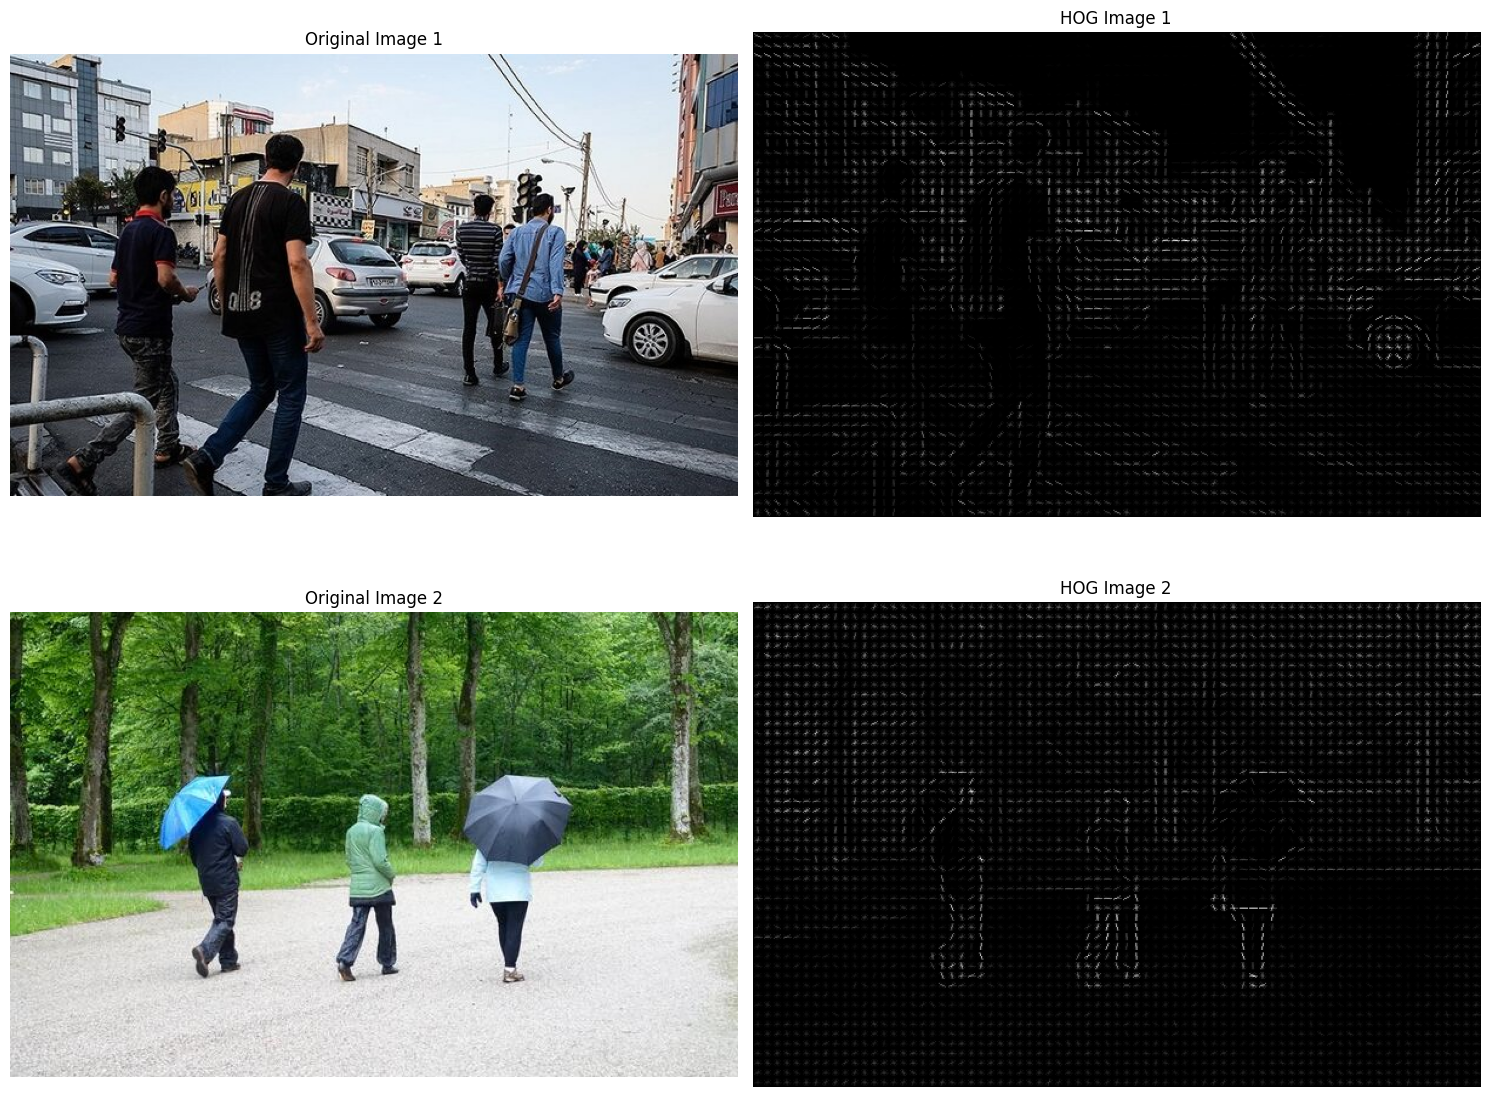

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for idx, img_path in enumerate(image_files):
    img = np.array(Image.open(img_path))
    gray = color.rgb2gray(img) if len(img.shape) == 3 else img
    resized = resize(gray, (400, 600), anti_aliasing=True)
    fd, hog_image = hog(resized, orientations=9, pixels_per_cell=(8, 8),
                        cells_per_block=(2, 2), visualize=True, feature_vector=False, block_norm='L2-Hys')

    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f'Original Image {idx+1}')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(hog_image, cmap='gray')
    axes[idx, 1].set_title(f'HOG Image {idx+1}')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

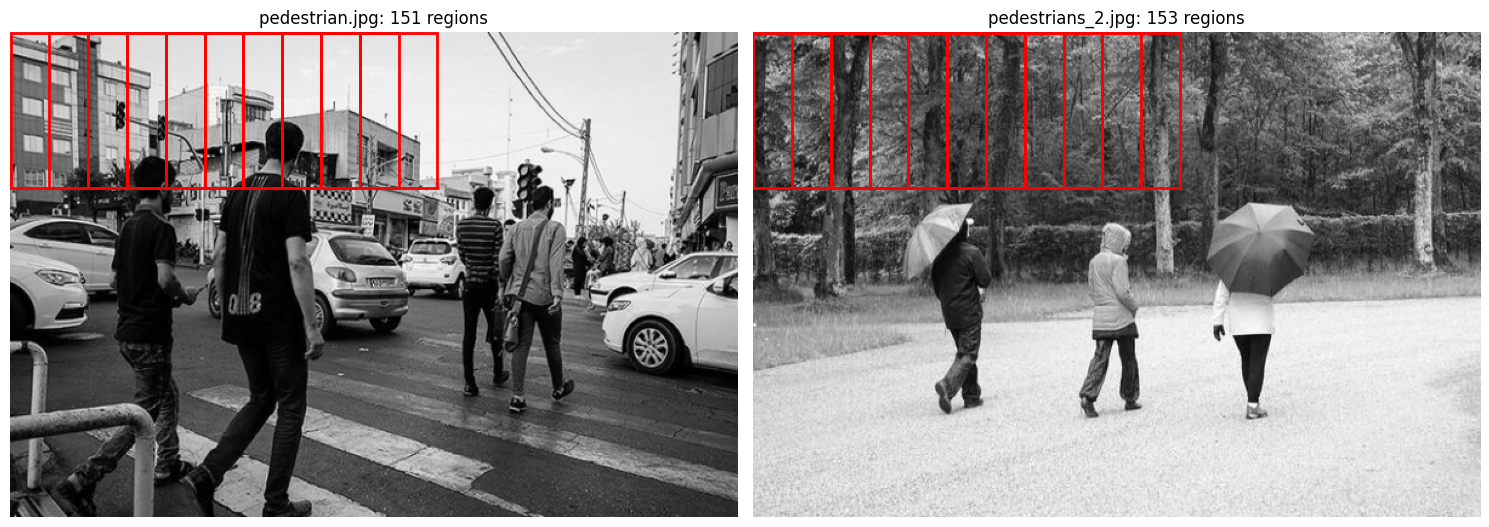

In [ ]:
window_size = (64, 128)
step_size = 32

fig, axes = plt.subplots(1, len(image_files), figsize=(15, 8))
if len(image_files) == 1:
    axes = [axes]

for idx, img_path in enumerate(image_files):
    img = np.array(Image.open(img_path))
    gray = color.rgb2gray(img) if len(img.shape) == 3 else img
    resized = resize(gray, (400, 600), anti_aliasing=True)

    gradient_magnitude = sobel(resized)
    threshold = np.percentile(gradient_magnitude, 85)

    detections = []

    for y in range(0, resized.shape[0] - window_size[1], step_size):
        for x in range(0, resized.shape[1] - window_size[0], step_size):
            window = resized[y:y+window_size[1], x:x+window_size[0]]
            if np.mean(window) > threshold:
                detections.append((x, y, window_size[0], window_size[1]))

    axes[idx].imshow(resized, cmap='gray')
    for (x, y, w, h) in detections[:10]:
        rect = plt.Rectangle((x, y), w, h, edgecolor='r', fill=False, linewidth=2)
        axes[idx].add_patch(rect)
    axes[idx].set_title(f"{img_path.split('/')[-1]}: {len(detections)} regions")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()